# 6. Validación robusta: ¿el mejor modelo realmente es el mejor?

En el cuaderno 4 apareció una **contradicción**:

| Modelo | AUC-ROC validación cruzada (5 pliegues) | AUC-ROC en prueba (una sola partición) |
|---|---|---|
| Gradient Boosting | **0.895** | 0.851 |
| Regresión Logística | 0.863 | **0.867** |

¿Cuál es mejor? Una sola partición de prueba tiene solo **179 pasajeros**, así que su resultado depende mucho de **qué pasajeros cayeron ahí por azar**.

**Plan de este cuaderno:**
1. **Validación cruzada repetida** 10 × 5 = 50 evaluaciones por modelo, cada repetición con una mezcla distinta de los datos.
2. Ver **qué tan seguido** cada modelo le gana al otro.
3. **Intervalos de confianza** del AUC de cada modelo.
4. **Prueba t corregida de Nadeau y Bengio** para decidir si la diferencia entre Gradient Boosting y Regresión Logística es estadísticamente significativa.

> **Nota (cuaderno 9):** en este cuaderno algunos cálculos se hicieron con los 891 pasajeros antes de separar entrenamiento y prueba (**fuga de información**). El cuaderno 9 mide ese efecto: es pequeño (+0.005 a +0.008 de AUC) y no significativo, y **las conclusiones se mantienen**. El modelo final (cuadernos 5 y 9) usa un pipeline sin fuga.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

sns.set_theme(style="whitegrid", palette="Set2")
SEED = 42

## 6.1 Datos y modelos (idénticos al cuaderno 4)
Se usa el mismo 80 % de entrenamiento del cuaderno 4. El 20 % de prueba **no se toca** aquí.

In [2]:
df = pd.read_csv("data/titanic_features.csv")
X = df.drop(columns="Survived")
y = df["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

escalar = lambda m: make_pipeline(StandardScaler(), m)
modelos = {
    "Regresión Logística": escalar(LogisticRegression(max_iter=2000, random_state=SEED)),
    "SVC":                 escalar(SVC(probability=True, random_state=SEED)),
    "Decision Tree":       DecisionTreeClassifier(max_depth=5, random_state=SEED),
    "KNeighbors":          escalar(KNeighborsClassifier(n_neighbors=7)),
    "Random Forest":       RandomForestClassifier(n_estimators=300, max_depth=7, random_state=SEED, n_jobs=1),
    "AdaBoost":            AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=SEED),
    "Gradient Boosting":   GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=SEED),
    "CatBoost":            CatBoostClassifier(iterations=400, depth=5, learning_rate=0.05, verbose=0,
                                              random_seed=SEED, allow_writing_files=False, thread_count=1),
    "XGBoost":             XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.9,
                                         colsample_bytree=0.9, eval_metric="logloss", random_state=SEED, n_jobs=1),
    "LightGBM":            LGBMClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, num_leaves=15,
                                          random_state=SEED, verbose=-1, n_jobs=1),
    "GaussianNB":          GaussianNB(),
}
print(X_train.shape)

(712, 35)


## 6.2 Validación cruzada repetida (10 repeticiones × 5 pliegues)
**Todos los modelos usan exactamente los mismos 50 pliegues** (misma semilla), así que las comparaciones son **pareadas**: en cada pliegue los modelos compiten con los mismos pasajeros.

In [3]:
N_REP, K = 10, 5
rcv = RepeatedStratifiedKFold(n_splits=K, n_repeats=N_REP, random_state=SEED)

auc, acc = {}, {}
for nombre, modelo in modelos.items():
    r = cross_validate(modelo, X_train, y_train, cv=rcv, scoring={"auc": "roc_auc", "acc": "accuracy"}, n_jobs=-1)
    auc[nombre] = r["test_auc"]
    acc[nombre] = r["test_acc"]
    print(f"{nombre:22s} AUC = {auc[nombre].mean():.4f} ± {auc[nombre].std():.4f}")

auc = pd.DataFrame(auc)
acc = pd.DataFrame(acc)
auc.to_csv("results/auc_cv_repetida.csv", index=False)

Regresión Logística    AUC = 0.8615 ± 0.0342


SVC                    AUC = 0.8634 ± 0.0330


Decision Tree          AUC = 0.8496 ± 0.0363


KNeighbors             AUC = 0.8411 ± 0.0354


Random Forest          AUC = 0.8837 ± 0.0328


...

Gradient Boosting      AUC = 0.8913 ± 0.0297


CatBoost               AUC = 0.8846 ± 0.0293


XGBoost                AUC = 0.8893 ± 0.0286


LightGBM               AUC = 0.8850 ± 0.0296


GaussianNB             AUC = 0.8152 ± 0.0364


## 6.3 Resumen con intervalos de confianza al 95 %

In [4]:
def ic95_corregido(valores, k=K, n_rep=N_REP, ratio=0.25):
    # Intervalo con la varianza corregida de Nadeau y Bengio:
    # los pliegues comparten datos de entrenamiento, así que NO son independientes
    # y la varianza ingenua subestima la incertidumbre.
    n = len(valores)
    media = valores.mean()
    var = valores.var(ddof=1) * (1 / n + ratio)
    t = stats.t.ppf(0.975, df=n - 1)
    return media - t * np.sqrt(var), media + t * np.sqrt(var)

filas = []
for m in auc.columns:
    lo, hi = ic95_corregido(auc[m].values)
    filas.append({"modelo": m, "AUC_media": auc[m].mean(), "AUC_std": auc[m].std(),
                  "IC95_inf": lo, "IC95_sup": hi, "Exactitud_media": acc[m].mean()})
resumen = pd.DataFrame(filas).set_index("modelo").sort_values("AUC_media", ascending=False)
resumen["ranking"] = range(1, len(resumen) + 1)
resumen.to_csv("results/resumen_cv_repetida.csv")
resumen.round(4)

,AUC_media,AUC_std,IC95_inf,IC95_sup,Exactitud_media,ranking
modelo,,,,,,
Gradient Boosting,0.8913,0.0300,0.8600,0.9227,0.8306,1
XGBoost,0.8893,0.0288,0.8592,0.9194,0.8312,2
LightGBM,0.8850,0.0299,0.8538,0.9163,0.8347,3
CatBoost,0.8846,0.0296,0.8537,0.9155,0.8285,4
Random Forest,0.8837,0.0332,0.8490,0.9183,0.8355,5
AdaBoost,0.8768,0.0317,0.8437,0.9100,0.8181,6
SVC,0.8634,0.0333,0.8286,0.8982,0.8236,7
Regresión Logística,0.8615,0.0345,0.8254,0.8975,0.8204,8
Decision Tree,0.8496,0.0367,0.8113,0.8879,0.8170,9


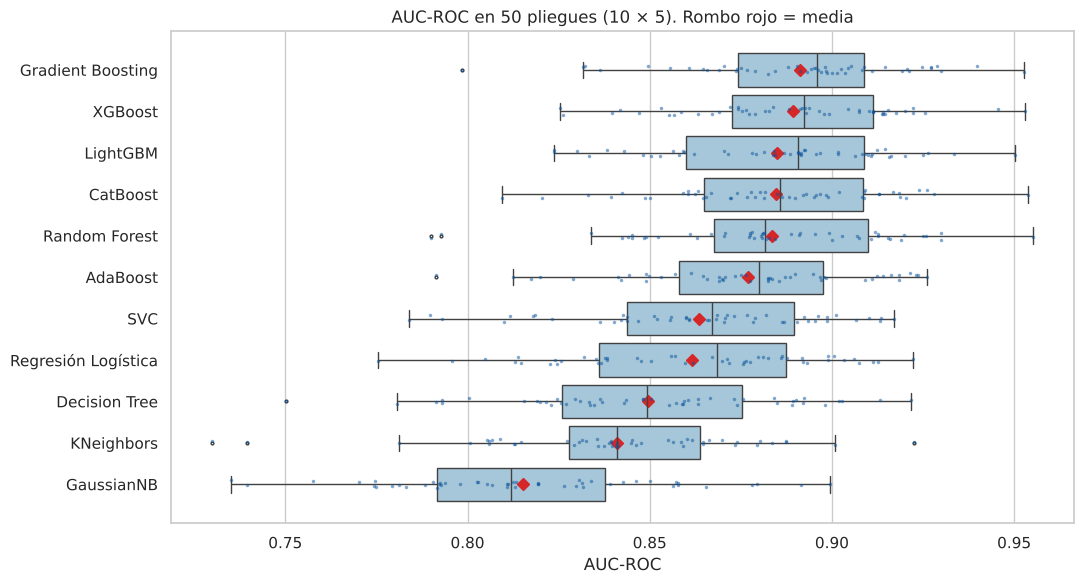

In [5]:
orden = resumen.index
fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=auc[orden], orient="h", ax=ax, color="#9ecae1", fliersize=2)
sns.stripplot(data=auc[orden], orient="h", ax=ax, color="#08519c", size=2.5, alpha=0.5)
for i, m in enumerate(orden):
    ax.plot(resumen.loc[m, "AUC_media"], i, "D", color="#d62728", ms=6)
ax.set_title("AUC-ROC en 50 pliegues (10 × 5). Rombo rojo = media")
ax.set_xlabel("AUC-ROC")
plt.tight_layout(); plt.show()

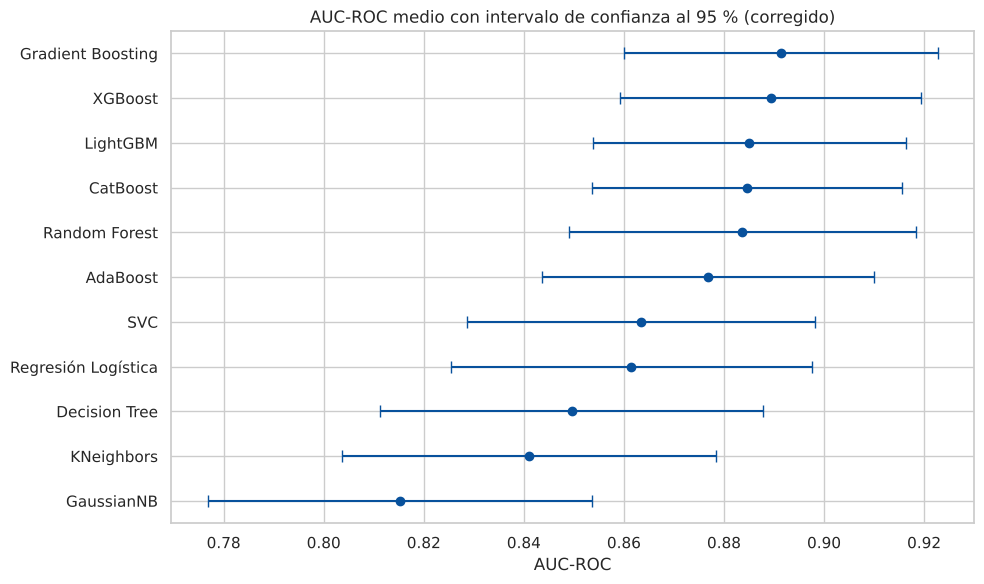

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
r = resumen.iloc[::-1]
ax.errorbar(r["AUC_media"], range(len(r)), xerr=[r["AUC_media"] - r["IC95_inf"], r["IC95_sup"] - r["AUC_media"]],
            fmt="o", capsize=4, color="#08519c")
ax.set_yticks(range(len(r))); ax.set_yticklabels(r.index)
ax.set_title("AUC-ROC medio con intervalo de confianza al 95 % (corregido)")
ax.set_xlabel("AUC-ROC")
plt.tight_layout(); plt.show()

## 6.4 ¿Por qué cambian los resultados de una partición a otra?
Para cada una de las 10 repeticiones calculamos el **ranking** de los modelos. Si una sola partición fuera confiable, el ranking sería casi siempre el mismo.

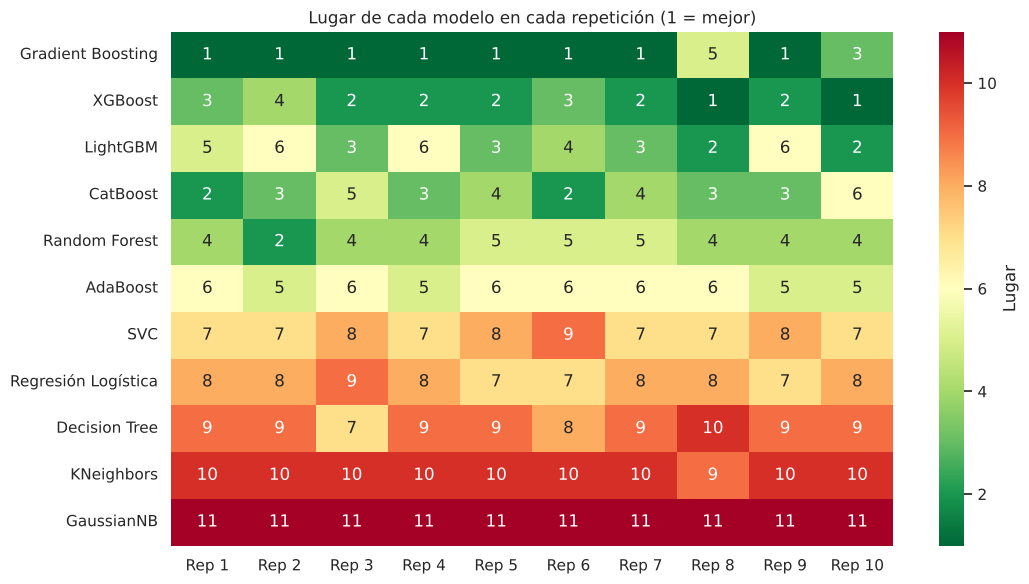

In [7]:
auc_rep = auc.groupby(np.arange(len(auc)) // K).mean()           # AUC medio por repetición
rank_rep = auc_rep.rank(axis=1, ascending=False)
pos = rank_rep[orden].T
pos.columns = [f"Rep {i+1}" for i in pos.columns]

plt.figure(figsize=(11, 6))
sns.heatmap(pos, annot=True, fmt=".0f", cmap="RdYlGn_r", cbar_kws={"label": "Lugar"})
plt.title("Lugar de cada modelo en cada repetición (1 = mejor)")
plt.tight_layout(); plt.show()

Pliegues donde gana Gradient Boosting:   48 de 50
Pliegues donde gana Regresión Logística: 2 de 50
Diferencia media de AUC (GB - LR):       +0.0299
Rango de la diferencia:                  -0.0270 a +0.0636


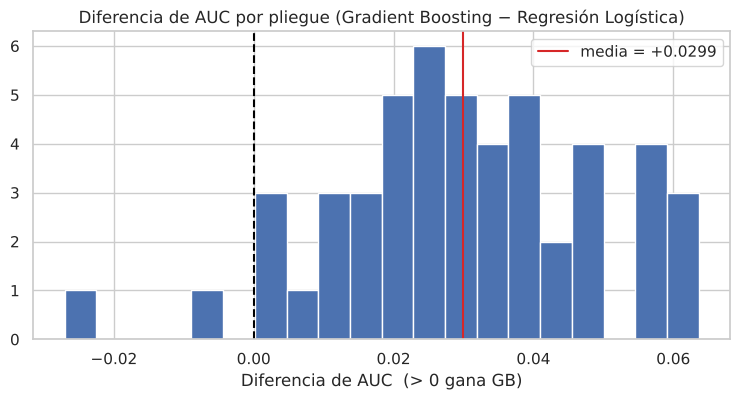

In [8]:
# Pliegue por pliegue: ¿quién gana, Gradient Boosting o Regresión Logística?
gb, lr = auc["Gradient Boosting"].values, auc["Regresión Logística"].values
dif = gb - lr
print(f"Pliegues donde gana Gradient Boosting:   {np.sum(dif > 0)} de {len(dif)}")
print(f"Pliegues donde gana Regresión Logística: {np.sum(dif < 0)} de {len(dif)}")
print(f"Diferencia media de AUC (GB - LR):       {dif.mean():+.4f}")
print(f"Rango de la diferencia:                  {dif.min():+.4f} a {dif.max():+.4f}")

plt.figure(figsize=(9, 4))
plt.hist(dif, bins=20, color="#4c72b0", edgecolor="white")
plt.axvline(0, color="k", ls="--")
plt.axvline(dif.mean(), color="#d62728", label=f"media = {dif.mean():+.4f}")
plt.title("Diferencia de AUC por pliegue (Gradient Boosting − Regresión Logística)")
plt.xlabel("Diferencia de AUC  (> 0 gana GB)")
plt.legend(); plt.show()

## 6.5 Prueba estadística: t corregida de Nadeau y Bengio

**Hipótesis:**
- H₀: los dos modelos tienen el mismo AUC esperado.
- H₁: tienen AUC distinto.

Una prueba t normal sobre 50 pliegues **exagera la significancia**, porque los pliegues comparten la mayoría de los datos de entrenamiento (no son independientes). Nadeau y Bengio (2003) corrigen la varianza multiplicándola por `(1/n + n_prueba/n_entrenamiento)`. Es la prueba recomendada para comparar modelos con validación cruzada repetida.

In [9]:
def t_corregida(a, b, ratio=0.25):
    d = a - b
    n = len(d)
    var = d.var(ddof=1) * (1 / n + ratio)
    t = d.mean() / np.sqrt(var)
    p = 2 * stats.t.sf(abs(t), df=n - 1)
    return d.mean(), t, p

# Prueba t ingenua (incorrecta) vs corregida, para ver la diferencia
t_ing, p_ing = stats.ttest_rel(gb, lr)
d, t_cor, p_cor = t_corregida(gb, lr)
print("Gradient Boosting vs Regresión Logística")
print(f"  t ingenua:   t = {t_ing:.3f}, p = {p_ing:.4f}")
print(f"  t corregida: t = {t_cor:.3f}, p = {p_cor:.4f}")

Gradient Boosting vs Regresión Logística
  t ingenua:   t = 11.080, p = 0.0000
  t corregida: t = 3.016, p = 0.0041


### Todos los modelos contra Gradient Boosting

In [10]:
ref = "Gradient Boosting"
filas = []
for m in orden:
    if m == ref:
        continue
    d, t, p = t_corregida(auc[ref].values, auc[m].values)
    filas.append({"modelo": m, "AUC_GB - AUC_modelo": d, "t": t, "p_valor": p,
                  "% pliegues que gana GB": np.mean(auc[ref].values > auc[m].values) * 100})
pruebas = pd.DataFrame(filas).set_index("modelo")
# Corrección de Holm por comparaciones múltiples (10 pruebas)
orden_p = pruebas["p_valor"].sort_values()
m_tot = len(orden_p)
holm = np.maximum.accumulate([min(1, p * (m_tot - i)) for i, p in enumerate(orden_p)])
pruebas.loc[orden_p.index, "p_Holm"] = holm
pruebas["¿Diferencia significativa? (α=0.05)"] = np.where(pruebas["p_Holm"] < 0.05, "Sí", "No")
pruebas.to_csv("results/pruebas_vs_gradient_boosting.csv")
pruebas.round(4)

,AUC_GB - AUC_modelo,t,p_valor,% pliegues que gana GB,p_Holm,¿Diferencia significativa? (α=0.05)
modelo,,,,,,
XGBoost,0.0020,0.2781,0.7821,56.0,1.0000,No
LightGBM,0.0063,0.7991,0.4281,70.0,1.0000,No
CatBoost,0.0067,0.9419,0.3509,68.0,1.0000,No
Random Forest,0.0077,1.0631,0.2929,68.0,1.0000,No
AdaBoost,0.0145,1.9395,0.0582,84.0,0.2910,No
SVC,0.0279,2.5753,0.0131,94.0,0.0785,No
Regresión Logística,0.0299,3.0157,0.0041,96.0,0.0324,Sí
Decision Tree,0.0418,2.8939,0.0057,94.0,0.0397,Sí
KNeighbors,0.0503,3.9369,0.0003,98.0,0.0023,Sí


## 6.6 ¿Y la partición de prueba del cuaderno 4?
Re-evaluamos ambos modelos en **50 particiones de prueba aleatorias distintas** (80/20, estratificadas) usando **todos** los datos, para ver cuánto puede variar el AUC de prueba solo por azar.

In [11]:
res = []
for s in range(50):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, stratify=y, random_state=s)
    fila = {"semilla": s}
    for m in ["Gradient Boosting", "Regresión Logística"]:
        modelos[m].fit(Xa, ya)
        fila[m] = roc_auc_score(yb, modelos[m].predict_proba(Xb)[:, 1])
    res.append(fila)
holdouts = pd.DataFrame(res)
holdouts["gana"] = np.where(holdouts["Gradient Boosting"] > holdouts["Regresión Logística"], "Gradient Boosting", "Regresión Logística")

print(holdouts[["Gradient Boosting", "Regresión Logística"]].describe().loc[["mean", "std", "min", "max"]].round(4))
print()
print(holdouts["gana"].value_counts())
print()
print("Semilla 42 (la del cuaderno 4):")
print(holdouts.loc[holdouts.semilla == 42, ["Gradient Boosting", "Regresión Logística"]].round(4).to_string(index=False))

      Gradient Boosting  Regresión Logística
mean             0.8763               0.8587
std              0.0251               0.0257
min              0.8222               0.8126
max              0.9366               0.9104

gana
Gradient Boosting      41
Regresión Logística     9
Name: count, dtype: int64

Semilla 42 (la del cuaderno 4):
 Gradient Boosting  Regresión Logística
            0.8505               0.8672


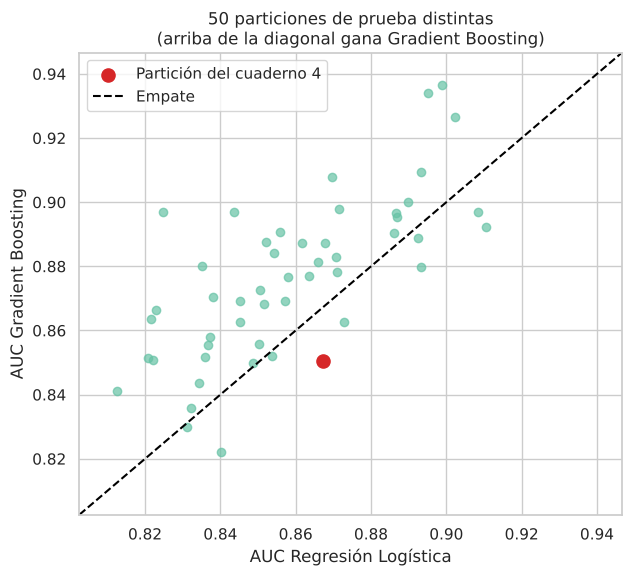

In [12]:
plt.figure(figsize=(7, 6))
plt.scatter(holdouts["Regresión Logística"], holdouts["Gradient Boosting"], alpha=0.7)
s42 = holdouts[holdouts.semilla == 42]
plt.scatter(s42["Regresión Logística"], s42["Gradient Boosting"], color="#d62728", s=90, label="Partición del cuaderno 4")
lim = [holdouts[["Gradient Boosting", "Regresión Logística"]].min().min() - 0.01,
       holdouts[["Gradient Boosting", "Regresión Logística"]].max().max() + 0.01]
plt.plot(lim, lim, "k--", label="Empate")
plt.xlim(lim); plt.ylim(lim)
plt.xlabel("AUC Regresión Logística"); plt.ylabel("AUC Gradient Boosting")
plt.title("50 particiones de prueba distintas\n(arriba de la diagonal gana Gradient Boosting)")
plt.legend(); plt.show()

## 6.7 Conclusiones

**1. La contradicción del cuaderno 4 fue mala suerte de la partición.**
En 50 particiones de prueba distintas, Gradient Boosting supera a la Regresión Logística en **41 de 50 (82 %)**. La partición del cuaderno 4 (semilla 42) es justo una de las 9 donde gana la Logística. Además, el AUC de prueba de un mismo modelo varía entre ~0.82 y ~0.94 solo por cambiar qué pasajeros caen en prueba (desviación ≈ 0.025). **Una sola partición de 179 pasajeros no basta para elegir modelo.**

**2. Con 50 pliegues, Gradient Boosting sigue en primer lugar.** AUC medio **0.891** (IC 95 %: 0.860–0.923), seguido de XGBoost (0.889), LightGBM (0.885), CatBoost (0.885) y Random Forest (0.884). La Regresión Logística queda en 8.º lugar con 0.862.

**3. Contra la Regresión Logística, la diferencia es real.** Gradient Boosting gana en **48 de 50 pliegues** y la diferencia media es **+0.030 de AUC**. La prueba t corregida da **p = 0.004** (p de Holm = 0.032 < 0.05): **se rechaza H₀**, la diferencia es estadísticamente significativa.
   - Ojo: la prueba t ingenua daba p ≈ 0.0000 (t = 11.1), **exagerando** la evidencia. Por eso hay que usar la corrección.

**4. Contra los otros ensambles NO hay diferencia significativa.** XGBoost, LightGBM, CatBoost, Random Forest y AdaBoost tienen p > 0.05: estadísticamente están **empatados** con Gradient Boosting. Sí hay diferencia significativa con Regresión Logística, Decision Tree, KNN y GaussianNB.

### Justificación final de la elección
Se elige **Gradient Boosting** porque:
- Tiene el **AUC medio más alto** en 50 evaluaciones y una de las variaciones más bajas.
- Es **significativamente mejor** que los modelos lineales, de distancia, el árbol individual y Naive Bayes.
- Frente a los demás ensambles está empatado estadísticamente. Entre modelos equivalentes se prefiere el de mejor media y el que **no requiere librerías externas** (viene en scikit-learn), lo que simplifica el despliegue en `app.py`.

**Siguiente paso:** ajuste del umbral de decisión (sensibilidad vs especificidad).